# Experiment 01: A neuron from scratch

**Question:** how does a cell made of salty water and fat send an electrical signal?

We'll answer it with the **Hodgkin–Huxley model** (1952): four equations that are still the basis of
computational neuroscience. Every line of the model lives in `src/sciencelab/neuro/hh.py`, so nothing here is a black box.

**The big picture.** A neuron's membrane separates two salt solutions:

| Ion | More of it... | Channel lets it... | Effect on voltage |
|---|---|---|---|
| Na⁺ (sodium) | outside | rush **in** | pushes voltage **up** (toward +50 mV) |
| K⁺ (potassium) | inside | leak **out** | pulls voltage **down** (toward −77 mV) |

The voltage at any moment is a tug-of-war between those channels. Each channel has **gates**
(`m`, `h`, `n`, each between 0 = shut and 1 = open) that respond to the voltage itself. That
feedback loop is what makes a spike.

**Where this is heading:** healthy cell → what breaks it → why → consequences → recovery → and when
something "dies," the forensics module works out what happened.

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np

from sciencelab.neuro import HHParams, count_spikes, simulate, step_current

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})
healthy = HHParams()
healthy

HHParams(C_m=1.0, g_Na=120.0, g_K=36.0, g_L=0.3, E_Na=50.0, E_K=-77.0, E_L=-54.387, temperature_c=6.3, q10=3.0)

## 1. A neuron at rest

No input. The cell should just sit at its **resting potential**, around −65 mV. Inside is negative
because potassium leaks out faster than anything else leaks in.

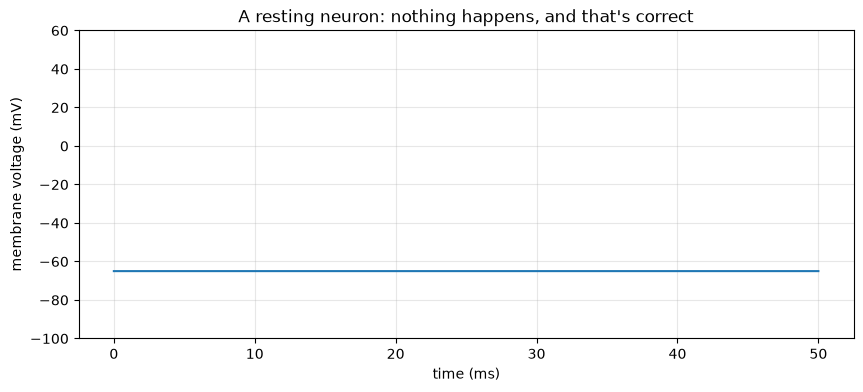

In [2]:
rest = simulate(healthy, t_stop=50)
plt.plot(rest.t, rest.V)
plt.ylim(-100, 60)
plt.xlabel("time (ms)")
plt.ylabel("membrane voltage (mV)")
plt.title("A resting neuron: nothing happens, and that's correct")
plt.show()

## 2. Poke it: the all-or-nothing spike

Inject a 1 ms pulse of current, the way an electrode would, at increasing strengths. Watch for the
point where a small bump suddenly becomes a full **action potential**.

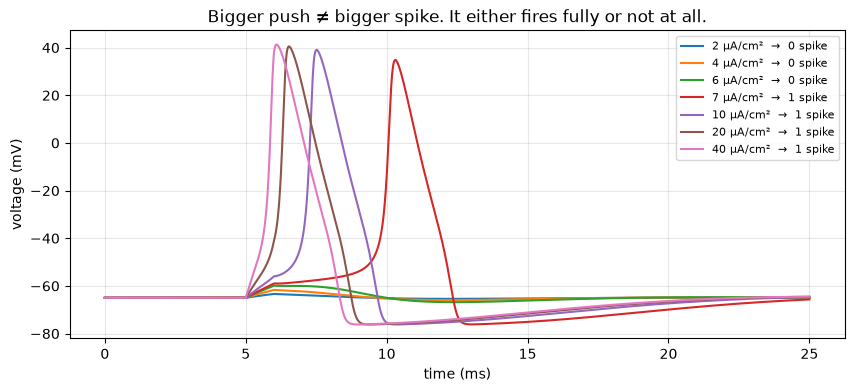

In [3]:
fig, ax = plt.subplots()
for amp in [2, 4, 6, 7, 10, 20, 40]:
    r = simulate(healthy, step_current(amp, start=5, duration=1), t_stop=25)
    ax.plot(r.t, r.V, label=f"{amp} µA/cm²  →  {count_spikes(r.V)} spike")
ax.set_xlabel("time (ms)")
ax.set_ylabel("voltage (mV)")
ax.set_title("Bigger push ≠ bigger spike. It either fires fully or not at all.")
ax.legend(fontsize=8)
plt.show()

Spikes from a 10 and a 40 µA/cm² push look almost the same. The neuron encodes "yes / no," not "how much."
Let's find the exact **threshold** by bisection (the same trick as binary search).

In [4]:
def fires(amp, params=healthy):
    return count_spikes(simulate(params, step_current(amp, start=5, duration=1), t_stop=25).V) > 0


lo, hi = 0.0, 40.0
for _ in range(20):
    mid = (lo + hi) / 2
    lo, hi = (lo, mid) if fires(mid) else (mid, hi)
print(f"Threshold for a 1 ms pulse ≈ {hi:.3f} µA/cm²")

Threshold for a 1 ms pulse ≈ 6.921 µA/cm²


## 3. Under the hood: who does what during a spike

This is the heart of it. Plot the three gates and the two big currents through one spike.
(By convention, *negative* current = positive ions flowing **into** the cell.)

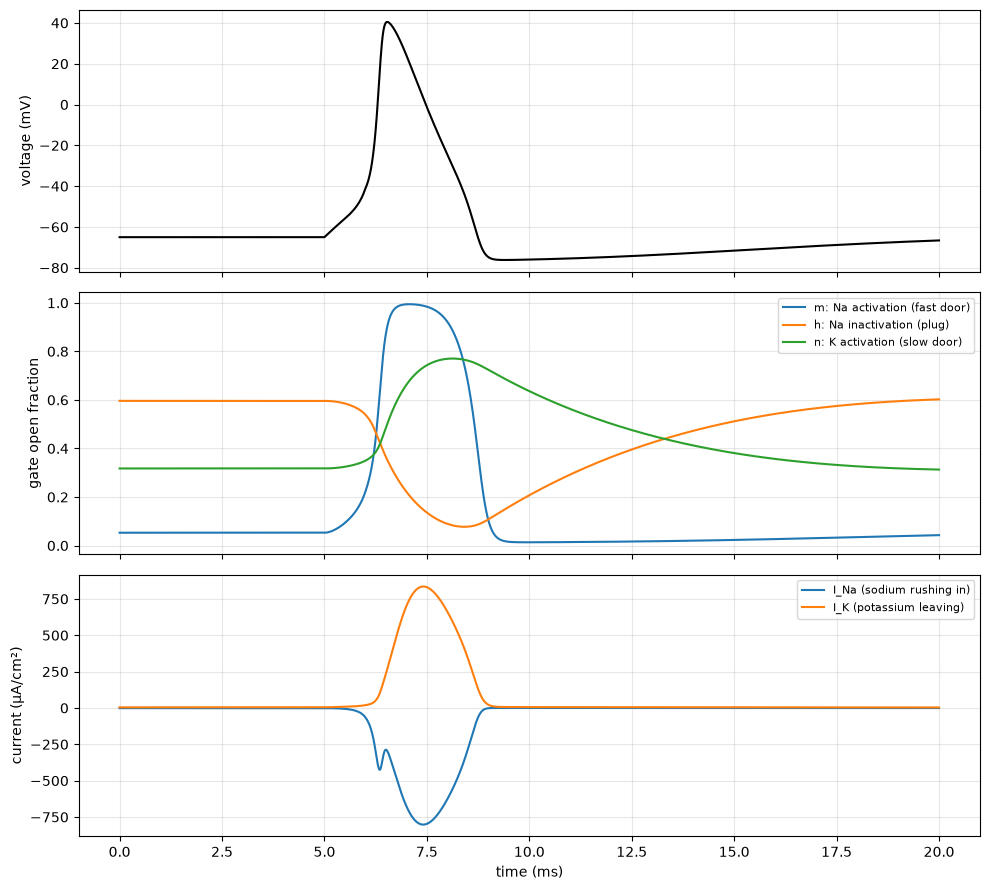

In [5]:
r = simulate(healthy, step_current(20, start=5, duration=1), t_stop=20)
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(r.t, r.V, "k")
axes[0].set_ylabel("voltage (mV)")

axes[1].plot(r.t, r.m, label="m: Na activation (fast door)")
axes[1].plot(r.t, r.h, label="h: Na inactivation (plug)")
axes[1].plot(r.t, r.n, label="n: K activation (slow door)")
axes[1].set_ylabel("gate open fraction")
axes[1].legend(fontsize=8)

axes[2].plot(r.t, r.I_Na, label="I_Na (sodium rushing in)")
axes[2].plot(r.t, r.I_K, label="I_K (potassium leaving)")
axes[2].set_ylabel("current (µA/cm²)")
axes[2].set_xlabel("time (ms)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Read the plots top to bottom, left to right:**

1. The pulse nudges voltage up → the fast `m` gates snap open → Na⁺ floods in → voltage rises more →
   more `m` opens. That's **positive feedback**: the explosive upstroke.
2. Slower, the `h` plug closes the Na channels, and the `n` gates open K channels → K⁺ leaves → voltage falls.
3. `n` stays open a bit too long → the voltage **undershoots** below rest, then recovers.

The whole event is over in about 2 ms (in the cold squid axon; faster in a warm human cell).

## 4. The refractory period: why spikes can't pile up

Give two identical pulses with a shrinking gap. If `h` hasn't recovered (Na channels still plugged),
the second pulse fails.

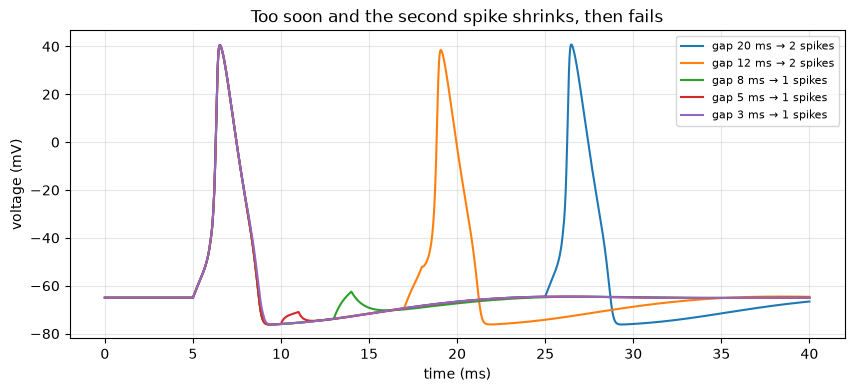

In [6]:
def two_pulses(gap, amp=20):
    first = step_current(amp, start=5, duration=1)
    second = step_current(amp, start=5 + gap, duration=1)
    return lambda t: first(t) + second(t)


fig, ax = plt.subplots()
for gap in [20, 12, 8, 5, 3]:
    r = simulate(healthy, two_pulses(gap), t_stop=40)
    ax.plot(r.t, r.V, label=f"gap {gap} ms → {count_spikes(r.V)} spikes")
ax.set_xlabel("time (ms)")
ax.set_ylabel("voltage (mV)")
ax.legend(fontsize=8)
ax.set_title("Too soon and the second spike shrinks, then fails")
plt.show()

## 5. Steady input: how a neuron encodes "how much"

A single spike is yes/no, but with a **sustained** input the neuron fires repeatedly, and the
**firing rate** carries the intensity. This plot is called an *f–I curve*.

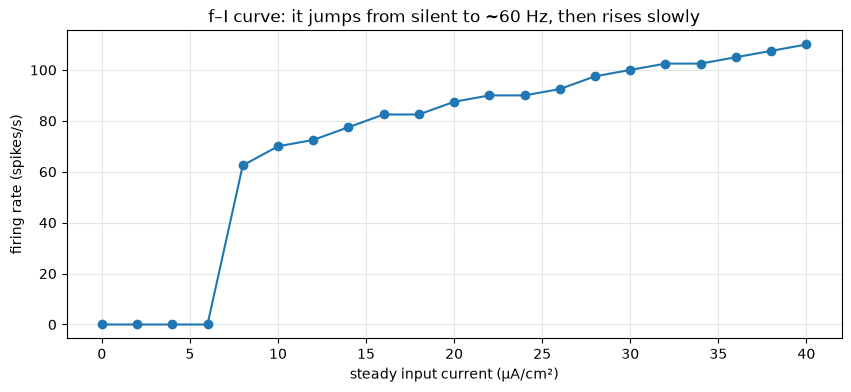

In [7]:
amps = np.arange(0, 41, 2)
rates = []
for amp in amps:
    r = simulate(healthy, step_current(amp, start=0, duration=500), t_stop=500)
    rates.append(count_spikes(r.V[r.t > 100]) / 0.4)  # skip the first 100 ms, spikes per second
plt.plot(amps, rates, "o-")
plt.xlabel("steady input current (µA/cm²)")
plt.ylabel("firing rate (spikes/s)")
plt.title("f–I curve: it jumps from silent to ~60 Hz, then rises slowly")
plt.show()

## 6. What if something goes wrong?

Now the fun part. Every perturbation below is just changing **one number** in `HHParams`. Each
has a real-world counterpart:

| Change | Real-world version |
|---|---|
| `g_Na` × 0.1 | **Tetrodotoxin** (pufferfish poison) or a heavy dose of local anesthetic blocks sodium channels |
| `g_K` × 0.25 | Potassium-channel blockers; also some inherited channel disorders |
| `E_K` raised to −60 | **High blood potassium** (hyperkalemia), e.g. kidney failure or cells bursting after injury |
| `temperature_c` raised | Fever or heat stroke. Rates speed up, and past a point the spike can't form at all |

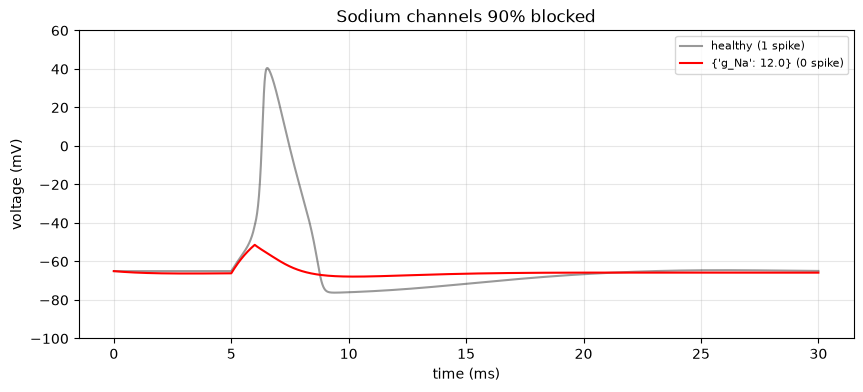

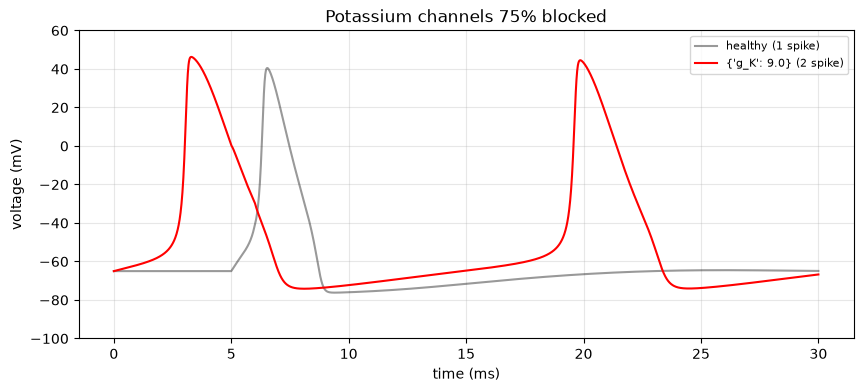

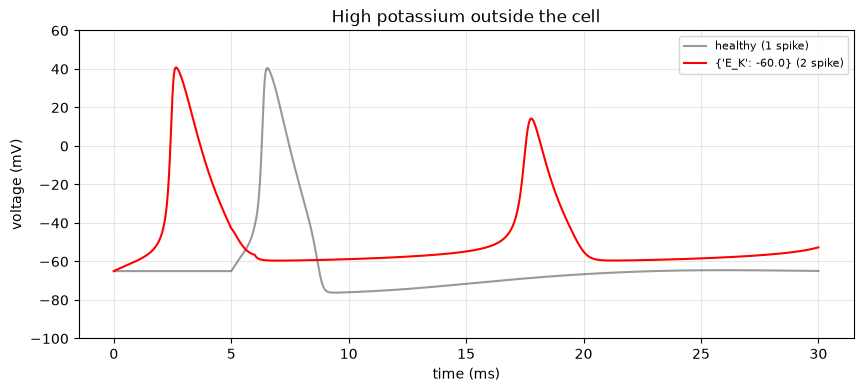

In [8]:
def compare(title, **changes):
    stim = step_current(20, start=5, duration=1)
    ok = simulate(healthy, stim, t_stop=30)
    broken = simulate(replace(healthy, **changes), stim, t_stop=30)
    plt.plot(ok.t, ok.V, "k", alpha=0.4, label=f"healthy ({count_spikes(ok.V)} spike)")
    plt.plot(broken.t, broken.V, "r", label=f"{changes} ({count_spikes(broken.V)} spike)")
    plt.ylim(-100, 60)
    plt.xlabel("time (ms)")
    plt.ylabel("voltage (mV)")
    plt.title(title)
    plt.legend(fontsize=8)
    plt.show()


compare("Sodium channels 90% blocked", g_Na=healthy.g_Na * 0.1)
compare("Potassium channels 75% blocked", g_K=healthy.g_K * 0.25)
compare("High potassium outside the cell", E_K=-60.0)

**Heat.** This squid axon evolved in cold water (the experiments ran at 6.3 °C). Let's warm it up.

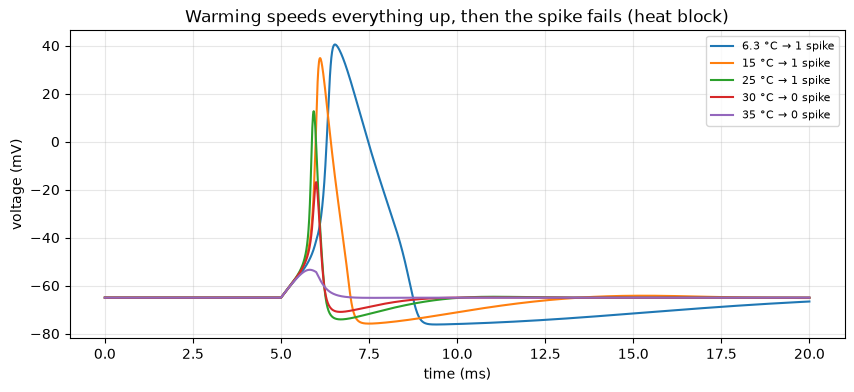

In [9]:
fig, ax = plt.subplots()
for temp in [6.3, 15, 25, 30, 35]:
    r = simulate(
        replace(healthy, temperature_c=temp), step_current(20, start=5, duration=1), t_stop=20
    )
    ax.plot(r.t, r.V, label=f"{temp} °C → {count_spikes(r.V)} spike")
ax.set_xlabel("time (ms)")
ax.set_ylabel("voltage (mV)")
ax.legend(fontsize=8)
ax.set_title("Warming speeds everything up, then the spike fails (heat block)")
plt.show()

Why does heat kill the spike? Warming speeds up *all* the gates. The fast Na door (`m`) usually
wins the race against the slow plug (`h`) and K door (`n`). Speed them all up and the slow ones
catch up before the upstroke can take off. Human neurons have different channels tuned to 37 °C,
so don't read these exact temperatures as human, but the *mechanism* is real. It's one reason
very high fevers cause confusion and seizures.

## Your turn

1. Find the threshold (section 2) with sodium 50% blocked. How much harder is the cell to fire?
2. In section 6, is there a `g_Na` level where the cell fires **sometimes**, depending on pulse size?
3. Push `E_K` from −77 toward −50 with *no* stimulus at all. What does the resting cell do? (Hint:
   this is why high potassium is dangerous for the heart.)
4. **Healing question:** after a 90% sodium block, what other single change could bring the spike
   back? Is it realistic?

**Next experiment ideas:** connect two neurons with a synapse; model energy failure (the Na/K pump
stopping during a stroke), which leads straight into what a pathologist sees in damaged tissue.